# 05 · Results and error analysis

What the final models score on test, where they go wrong, and why (research question 4).

This notebook builds on the three before it: `02_baseline.ipynb` (KNN and logistic regression on
pixels, HOG and colour histograms), `03_cnn.ipynb` (simple CNN from scratch, with and without
augmentation) and `04_transfer.ipynb` (ResNet-50 at 128 and 224 px, test-time augmentation, seed
ensemble). Sections 1–3 gather their test results in one place; sections 4–9 are the error analysis.

1. Final results: every model on the test set, CNNs as mean ± std over 3 seeds, plus
   test-time augmentation (TTA) and a seed ensemble for ResNet-50, at 128 and 224 px
2. Before vs after augmentation (128 px), and input size 128 vs 224 vs 256 px
3. Per-class F1 and pooled confusion matrices
4. Stable vs unstable mistakes (do all 3 ResNet seeds make the same error?)
5. Same-session frames: does every test image have a near-identical training image?
6. Grad-CAM: what the ResNet-50 and simple CNN look at when they are wrong
7. LIME: what the colour-histogram KNN responds to
8. Error-cause gallery + tagging sheet for the team
9. Are mistakes darker, blurrier or less colourful than correct predictions?
10. Takeaways

The ResNet-50 analysed in sections 3–9 is the **final model**: flip / rotate / crop at 224×224 px
(`experiments/ITERATION_LOG.md` rows 15–16). The same analysis of the 128 px model is in git
history (commit 92b7e87).

**Split.** Every result uses the authors' split as published on Kaggle (`labels/*_subset0.csv`,
fold 0): 10,501 train, 3,501 val and 3,507 test images, no image in two splits. Labels come from
`labels.csv` (one image has a different label in the fold files; see `src/data/kaggle_split.py`).

**Leakage note.** No test image is used for training or for any choice: k, C, the best epoch,
the input size and the use of TTA / the seed ensemble are picked on the validation set, and each
CNN's augmentation was chosen on validation data in earlier tuning runs, before these runs. This
notebook reads saved results and predictions, loads the saved CNN checkpoints for Grad-CAM
(section 6) and refits the KNN on train for LIME (section 7). Nothing here feeds back into a model.

**Running it.** Sections 6–7 need the `*_kaggle0_s1.pt` checkpoints in `experiments/checkpoints/`
(not in git) and the `grad-cam` and `lime` packages; every other section only needs the files in
the repo and `data/images/`.


In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image as ShowImage, display
from scipy.stats import mannwhitneyu

ROOT = Path('..').resolve()
sys.path.insert(0, str(ROOT))
from src.evaluation import explain
from src.evaluation.aggregate import top_pooled_confusions

%matplotlib inline
# ^ src.evaluation.confusion selects the non-interactive Agg backend on import; switch back so figures show
%config InlineBackend.figure_formats = ['jpeg']  # most figures are photo grids; keeps the notebook small

METRICS = ROOT / 'results' / 'metrics'
PREDS = ROOT / 'results' / 'predictions'
CMS = ROOT / 'results' / 'confusion_matrices'
CFG = ROOT / 'experiments' / 'configs'
IMG_DIR = ROOT / 'data' / 'images'
FIG_DIR = ROOT / 'results' / 'figures' / 'error_analysis_kaggle0'
FIG_DIR.mkdir(parents=True, exist_ok=True)

SPLIT = '_kaggle0'                                         # Kaggle split, fold 0
RESNET128 = 'resnet50_aug_geo_crop_30ep_bf16' + SPLIT      # flip + rotate + random crop, 128 px
RESNET = 'resnet50_aug_geo_crop_30ep_bf16_224' + SPLIT     # same at 224 px: the final model
RESNET256 = 'resnet50_aug_geo_crop_30ep_bf16_256' + SPLIT  # same at 256 px (seed 1, val only, rejected)
CNN = 'simple_cnn_aug_geo_colour_60ep_bf16' + SPLIT        # flip + rotate + colour jitter
SEEDS = [1, 2, 3]

def metrics(run):
    return json.loads((METRICS / f'{run}.json').read_text())

CLASSES = metrics(f'{RESNET}_s1')['config']['classes']
pd.set_option('display.precision', 3)
plt.rcParams['figure.dpi'] = 90

## 1. Final results on test

The TTA rows add test-time augmentation to the same 3 ResNet-50 checkpoints: each image is
scored in its 8 flip / 90° rotation views (the orientations training already uses) and the
softmax outputs are averaged; the ensemble also averages the 3 seeds. No retraining. TTA and
the ensemble were chosen on val at 128 px (`experiments/ITERATION_LOG.md` rows 12–13) and
again at 224 px (row 16) before test was scored. The 224 px rows differ from the 128 px ones
only in input size (row 15). Sections 3–9 analyse the 224 px single-model predictions without TTA.

Where each row comes from: classical models in `02_baseline.ipynb` (section 4), simple CNN in `03_cnn.ipynb` (section 6), ResNet-50 at 128 px, TTA and the ensemble in `04_transfer.ipynb` (sections 5–6), and at 224 px in `04_transfer.ipynb` section 7.


In [2]:
KEYS = ['macro_f1', 'macro_precision', 'macro_recall', 'accuracy']

def single(label, run):
    d = metrics(run)['splits']
    row = {'model': label, 'runs': 1, 'val macro F1': d['val']['model']['macro_f1']}
    row.update({k: f"{d['test']['model'][k]:.3f}" for k in KEYS})
    return row

def seeds(label, prefix):
    s = metrics(f'{prefix}_seeds')['splits']
    row = {'model': label, 'runs': len(SEEDS), 'val macro F1': s['val']['macro_f1']['mean']}
    row.update({k: f"{s['test'][k]['mean']:.3f} ± {s['test'][k]['std']:.3f}" for k in KEYS})
    return row

def tta(label, combo, prefix=RESNET):
    t, v = (metrics(f'{prefix}_tta_{split}')['results'] for split in ('test', 'val'))
    if f'{combo} (mean)' in t:   # each seed on its own: mean ± std
        return {'model': label, 'runs': len(SEEDS), 'val macro F1': v[f'{combo} (mean)']['macro_f1'],
                **{k: f"{t[f'{combo} (mean)'][k]:.3f} ± {t[f'{combo} (std)'][k]:.3f}" for k in KEYS}}
    return {'model': label, 'runs': len(SEEDS), 'val macro F1': v[combo]['macro_f1'],
            **{k: f'{t[combo][k]:.3f}' for k in KEYS}}

majority = metrics('knn_hist' + SPLIT)['splits']['test']['majority_baseline']
rows = [{'model': 'Majority class (always Negative)', 'runs': 1, 'val macro F1': np.nan,
         **{k: f'{majority[k]:.3f}' for k in KEYS}}]
rows += [single('KNN, raw pixels', 'knn_pixels' + SPLIT), single('KNN, HOG', 'knn_hog' + SPLIT),
         single('KNN, HSV colour histogram', 'knn_hist' + SPLIT),
         single('Logistic regression, raw pixels', 'logreg_pixels' + SPLIT), single('Logistic regression, HOG', 'logreg_hog' + SPLIT),
         single('Logistic regression, HSV colour histogram', 'logreg_hist' + SPLIT),
         single('Simple CNN, no augmentation', 'simple_cnn_noaug_60ep_bf16' + SPLIT + '_s1'),
         seeds('Simple CNN + flip/rotate/colour', CNN),
         single('ResNet-50, no augmentation', 'resnet50_noaug_30ep_bf16' + SPLIT + '_s1'),
         seeds('ResNet-50 + flip/rotate/crop', RESNET128),
         tta('ResNet-50 + flip/rotate/crop, with TTA', 'single + TTA', RESNET128),
         tta('ResNet-50, ensemble of 3 seeds, with TTA', 'ensemble + TTA', RESNET128),
         seeds('ResNet-50 + flip/rotate/crop, 224 px', RESNET),
         tta('ResNet-50 + flip/rotate/crop, 224 px, with TTA', 'single + TTA'),
         tta('ResNet-50, 224 px, ensemble of 3 seeds, with TTA', 'ensemble + TTA')]
results = pd.DataFrame(rows).set_index('model').rename(columns={k: f'test {k}' for k in KEYS})
results.to_csv(FIG_DIR / 'final_results.csv')
results

,runs,val macro F1,test macro_f1,test macro_precision,test macro_recall,test accuracy
model,,,,,,
Majority class (always Negative),1,NaN,0.076,0.058,0.111,0.520
"KNN, raw pixels",1,0.192,0.192,0.204,0.207,0.434
"KNN, HOG",1,0.125,0.128,0.149,0.131,0.388
"KNN, HSV colour histogram",1,0.608,0.613,0.650,0.586,0.721
"Logistic regression, raw pixels",1,0.239,0.234,0.268,0.220,0.504
"Logistic regression, HOG",1,0.160,0.166,0.185,0.162,0.434
"Logistic regression, HSV colour histogram",1,0.384,0.375,0.464,0.341,0.595
"Simple CNN, no augmentation",1,0.877,0.870,0.875,0.865,0.900
Simple CNN + flip/rotate/colour,3,0.907,0.905 ± 0.005,0.915 ± 0.004,0.895 ± 0.006,0.925 ± 0.004


## 2. Before vs after augmentation

A summary of `03_cnn.ipynb` sections 4–6 and `04_transfer.ipynb` sections 4–5, which show the full training curves and the train/val loss gap.

Same model, schedule and seed 1, at 128 px; the only change is train-time augmentation (one factor).
The augmented configs were also run with seeds 2 and 3, so their spread shows how much of
a gap seed noise alone could explain. The no-augmentation runs have one seed each.

In [3]:
pairs = [('Simple CNN', 'simple_cnn_noaug_60ep_bf16' + SPLIT, CNN), ('ResNet-50', 'resnet50_noaug_30ep_bf16' + SPLIT, RESNET128)]
rows = []
for name, noaug, aug in pairs:
    n, a = metrics(f'{noaug}_s1')['splits'], metrics(f'{aug}_s1')['splits']
    s = metrics(f'{aug}_seeds')['splits']
    for split in ('val', 'test'):
        rows.append({'model': name, 'split': split,
                     'no aug (s1)': n[split]['model']['macro_f1'],
                     'aug (s1)': a[split]['model']['macro_f1'],
                     'gain (s1)': a[split]['model']['macro_f1'] - n[split]['model']['macro_f1'],
                     'aug mean (3 seeds)': s[split]['macro_f1']['mean'],
                     'aug std': s[split]['macro_f1']['std'],
                     'aug min': s[split]['macro_f1']['min']})
aug_table = pd.DataFrame(rows).set_index(['model', 'split'])
aug_table

no aug (s1)  aug (s1)  gain (s1)  aug mean (3 seeds)  \
model      split                                                         
Simple CNN val          0.877     0.906      0.029               0.907   
           test         0.870     0.902      0.032               0.905   
ResNet-50  val          0.876     0.925      0.050               0.924   
           test         0.870     0.929      0.058               0.923   

                    aug std  aug min  
model      split                      
Simple CNN val    5.980e-04    0.906  
           test   5.039e-03    0.902  
ResNet-50  val    3.473e-03    0.920  
           test   5.265e-03    0.919

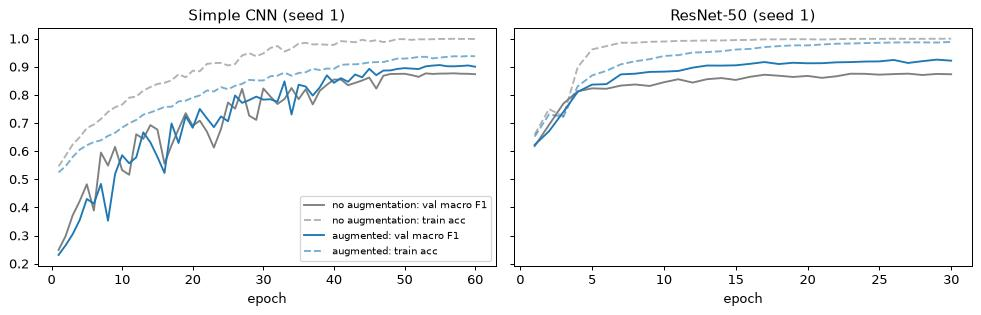

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, (name, noaug, aug) in zip(axes, pairs):
    for run, label, colour in [(f'{noaug}_s1', 'no augmentation', 'tab:grey'), (f'{aug}_s1', 'augmented', 'tab:blue')]:
        h = pd.DataFrame(metrics(run)['history'])
        ax.plot(h['epoch'], h['val_macro_f1'], color=colour, label=f'{label}: val macro F1')
        ax.plot(h['epoch'], h['train_acc'], color=colour, ls='--', alpha=0.6, label=f'{label}: train acc')
    ax.set_title(f'{name} (seed 1)')
    ax.set_xlabel('epoch')
axes[0].legend(fontsize=8, loc='lower right')
fig.tight_layout()
fig.savefig(FIG_DIR / 'augmentation_curves.png', bbox_inches='tight')

### Input size: 128 vs 224 vs 256 px

ResNet-50 with flip / rotate / crop; the only change is the input size. 256 px is the native
size of every DeepWeeds image, so its val images are not resized at all. 128 and 224 px have
3 seeds; 256 px was run with seed 1 only and rejected on val (`ITERATION_LOG.md` row 17), so it
has no test score. `04_transfer.ipynb` section 7 shows every seed's curves and the cost.


,seeds,val macro F1 (s1),val mean,val std,test mean,test std
input,,,,,,
128 px,3,0.925,0.924,0.003,0.923,0.005
224 px,3,0.966,0.966,0.001,0.965,0.002
256 px,1,0.954,0.954,NaN,NaN,NaN


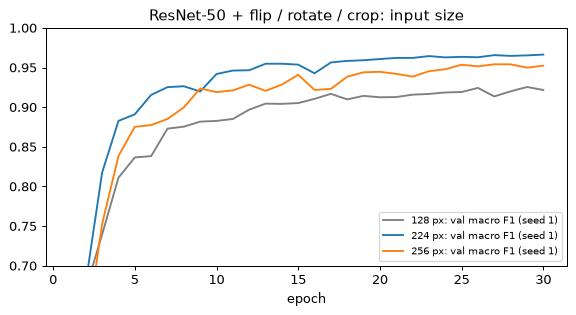

In [5]:
size_runs = [('128 px', RESNET128), ('224 px', RESNET), ('256 px', RESNET256)]
rows = []
for label, prefix in size_runs:
    runs = [s for s in SEEDS if (METRICS / f'{prefix}_s{s}.json').exists()]
    val = [max(h['val_macro_f1'] for h in metrics(f'{prefix}_s{s}')['history']) for s in runs]
    row = {'input': label, 'seeds': len(runs), 'val macro F1 (s1)': val[0],
           'val mean': np.mean(val), 'val std': np.std(val, ddof=1) if len(val) > 1 else np.nan}
    if (METRICS / f'{prefix}_seeds.json').exists():
        t = metrics(f'{prefix}_seeds')['splits']['test']['macro_f1']
        row.update({'test mean': t['mean'], 'test std': t['std']})
    rows.append(row)
size_table = pd.DataFrame(rows).set_index('input')

fig, ax = plt.subplots(figsize=(6.5, 3.6))
for (label, prefix), colour in zip(size_runs, ['tab:grey', 'tab:blue', 'tab:orange']):
    h = pd.DataFrame(metrics(f'{prefix}_s1')['history'])
    ax.plot(h['epoch'], h['val_macro_f1'], color=colour, label=f'{label}: val macro F1 (seed 1)')
ax.set_ylim(0.7, 1.0); ax.set_xlabel('epoch'); ax.legend(fontsize=8, loc='lower right')
ax.set_title('ResNet-50 + flip / rotate / crop: input size')
fig.tight_layout()
fig.savefig(FIG_DIR / 'input_size_curves.png', bbox_inches='tight')
size_table


## 3. Per-class F1 and pooled confusion matrices

,KNN colour hist,Simple CNN (mean),ResNet-50 128 px (mean),ResNet-50 (mean),ResNet-50 ensemble + TTA,ResNet-50 std,test images
Snake weed,0.479,0.825,0.881,0.938,0.948,0.002,204
Chinee apple,0.427,0.856,0.871,0.944,0.958,0.006,226
Prickly acacia,0.712,0.894,0.925,0.948,0.958,0.012,213
Parthenium,0.607,0.924,0.919,0.962,0.978,0.005,205
Rubber vine,0.570,0.916,0.925,0.973,0.978,0.006,202
Lantana,0.624,0.898,0.924,0.977,0.981,0.004,213
Parkinsonia,0.692,0.965,0.952,0.980,0.983,0.005,207
Siam weed,0.577,0.919,0.947,0.982,0.986,0.006,215
Negative,0.827,0.948,0.961,0.983,0.985,0.002,1822


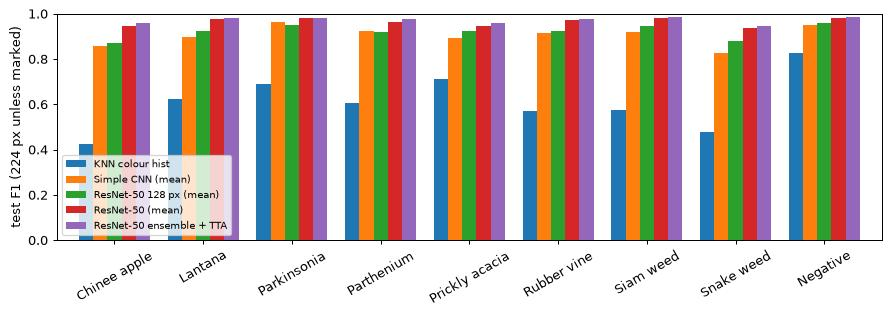

In [6]:
knn_pc = metrics('knn_hist' + SPLIT)['splits']['test']['model']['per_class']
ens_pc = metrics(f'{RESNET}_tta_test')['results']['ensemble + TTA']['per_class']
per_class = pd.DataFrame({
    'KNN colour hist': {c: knn_pc[c]['f1'] for c in CLASSES},
    'Simple CNN (mean)': {c: v['mean'] for c, v in metrics(f'{CNN}_seeds')['per_class_test_f1'].items()},
    'ResNet-50 128 px (mean)': {c: v['mean'] for c, v in metrics(f'{RESNET128}_seeds')['per_class_test_f1'].items()},
    'ResNet-50 (mean)': {c: v['mean'] for c, v in metrics(f'{RESNET}_seeds')['per_class_test_f1'].items()},
    'ResNet-50 ensemble + TTA': {c: ens_pc[c]['f1'] for c in CLASSES},
    'ResNet-50 std': {c: v['std'] for c, v in metrics(f'{RESNET}_seeds')['per_class_test_f1'].items()},
    'test images': {c: knn_pc[c]['support'] for c in CLASSES},
}).loc[CLASSES]
ax = per_class.iloc[:, :5].plot.bar(figsize=(10, 3.6), width=0.8, rot=30)
ax.set_ylabel('test F1 (224 px unless marked)'); ax.set_ylim(0, 1); ax.legend(fontsize=8, loc='lower left')
plt.tight_layout(); plt.savefig(FIG_DIR / 'per_class_f1.png', bbox_inches='tight')
per_class.sort_values('ResNet-50 (mean)')

resnet50_aug_geo_crop_30ep_bf16_224_kaggle0 - top mistakes, mean count per run (true -> pred):
      Chinee apple -> Negative         9.7
        Snake weed -> Negative         9.3
          Negative -> Prickly acacia   7.7
    Prickly acacia -> Negative         7.0
        Snake weed -> Chinee apple     4.7
       Rubber vine -> Negative         4.3
simple_cnn_aug_geo_colour_60ep_bf16_kaggle0 - top mistakes, mean count per run (true -> pred):
        Snake weed -> Negative        21.3
      Chinee apple -> Negative        21.3
           Lantana -> Negative        18.0
    Prickly acacia -> Negative        15.0
        Parthenium -> Negative        15.0
          Negative -> Prickly acacia  14.7


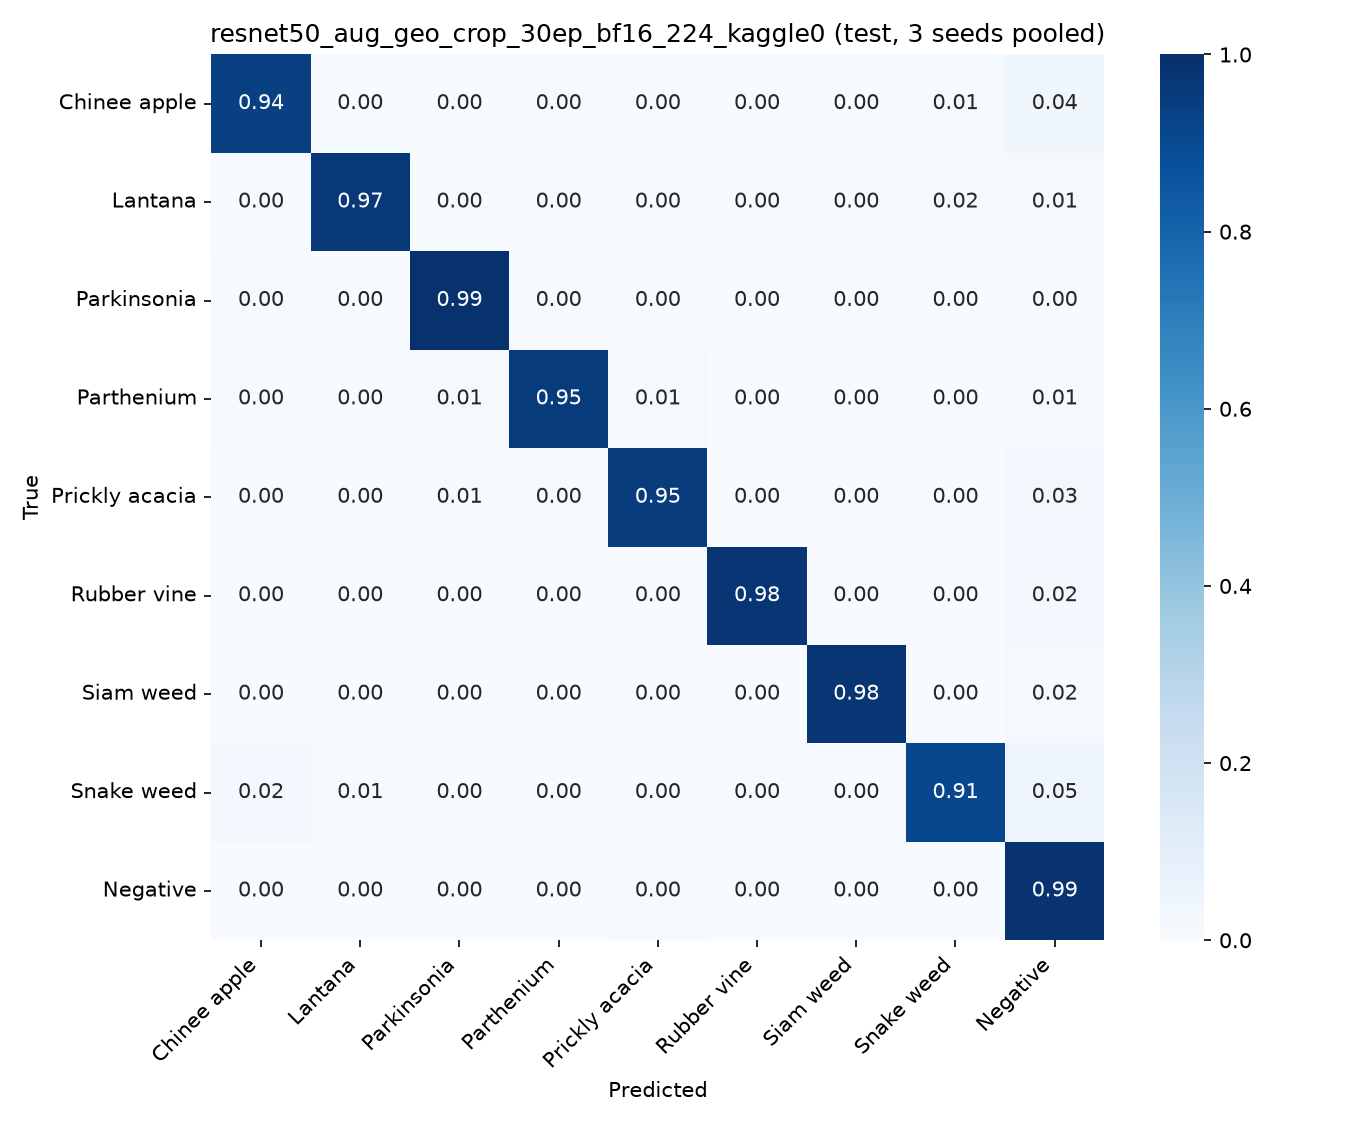

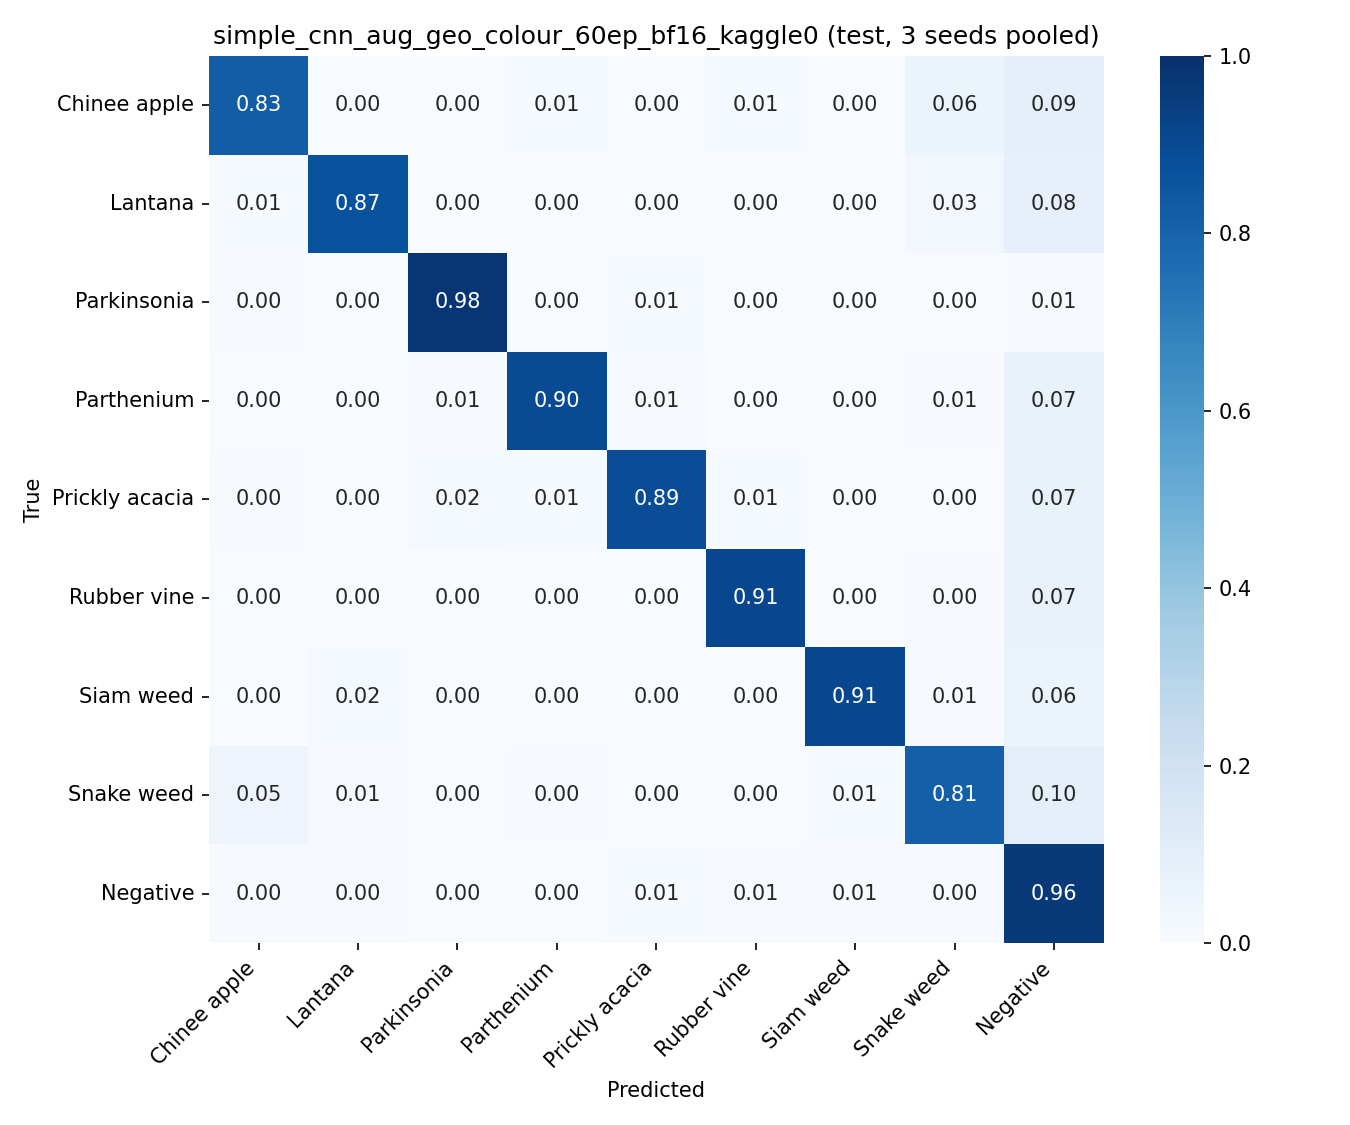

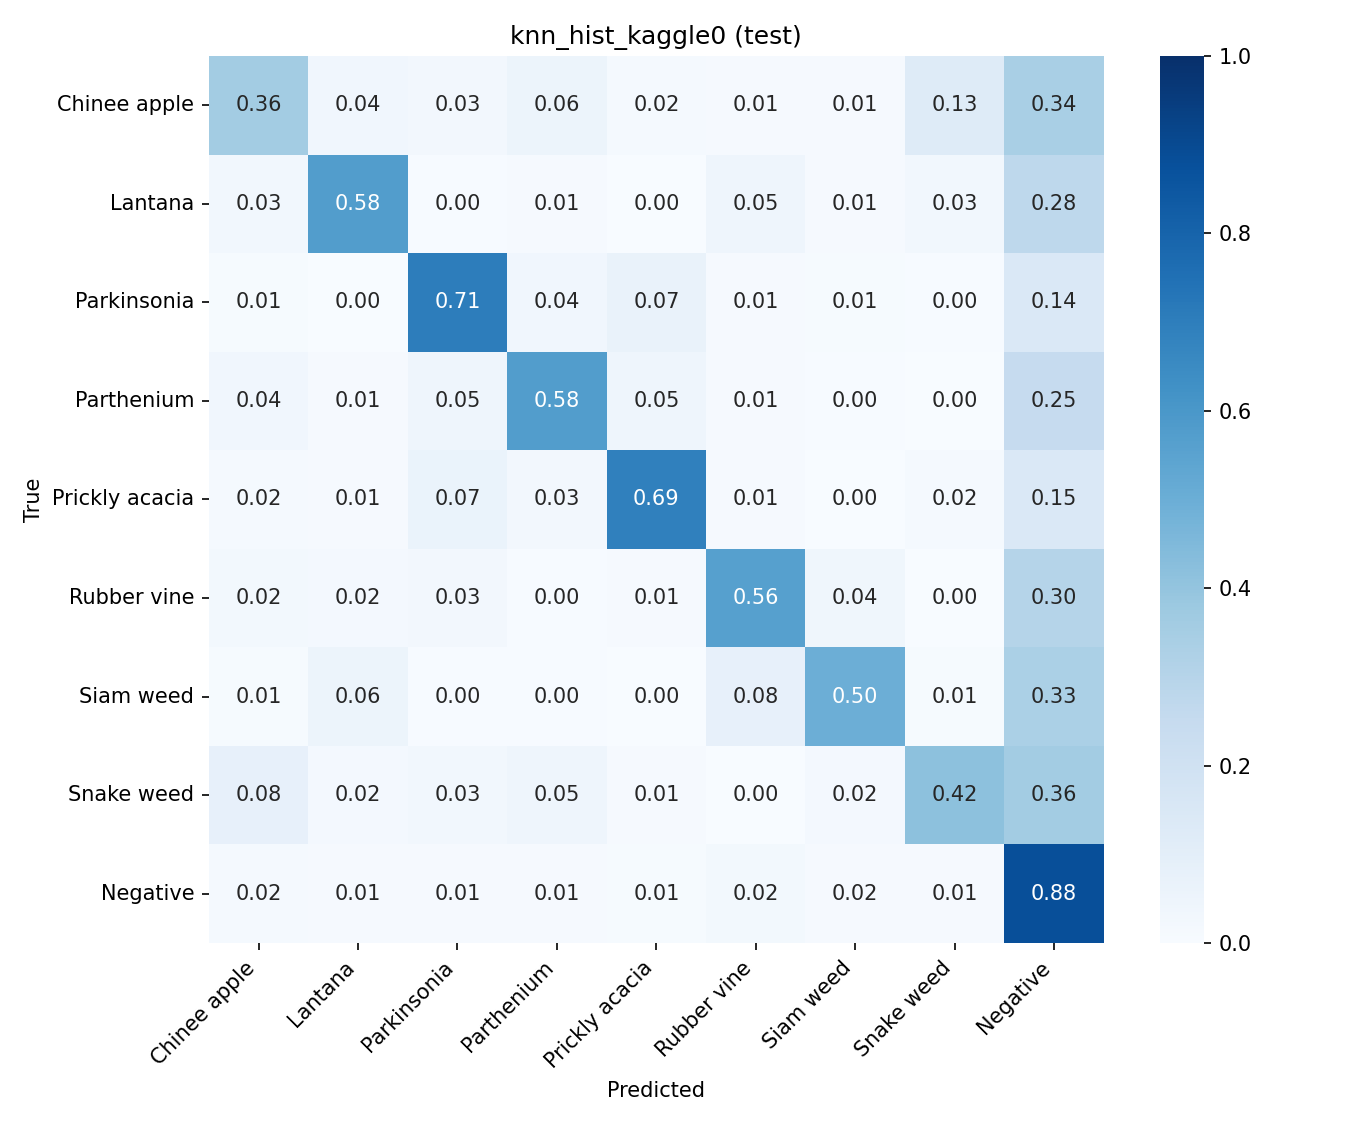

In [7]:
for prefix in (RESNET, CNN):
    print(prefix, '- top mistakes, mean count per run (true -> pred):')
    for t, p, n in top_pooled_confusions(metrics(f'{prefix}_seeds'), k=6):
        print(f'    {t:>14} -> {p:<14} {n:5.1f}')
display(ShowImage(filename=str(CMS / f'{RESNET}_seeds_test.png'), width=520))
display(ShowImage(filename=str(CMS / f'{CNN}_seeds_test.png'), width=520))
display(ShowImage(filename=str(CMS / f'knn_hist{SPLIT}_test.png'), width=520))

## 4. Stable vs unstable mistakes

All three ResNet seeds (224 px) see the same test set. A mistake made by **all three** comes from the
image (look-alike species, an ambiguous or mislabelled photo). A mistake made by **one** seed
reflects training randomness. Most of the analysis below uses the stable mistakes.

In [8]:
def load_preds(prefix, seed):
    return pd.read_csv(PREDS / f'{prefix}_s{seed}_test.csv').set_index('Filename')

res = {s: load_preds(RESNET, s) for s in SEEDS}
test = res[1][['true']].copy()
test['n_wrong'] = sum((res[s]['pred'] != res[s]['true']).astype(int) for s in SEEDS)
test['mean_conf'] = sum(res[s]['confidence'] for s in SEEDS) / len(SEEDS)
test['pred_s1'] = res[1]['pred']
counts = test['n_wrong'].value_counts().sort_index().rename('test images')
print(counts.to_string())
print(f"\nwrong in all 3 seeds: {(test.n_wrong == 3).sum()} of {(test.n_wrong > 0).sum()} images wrong in any seed "
      f"({(test.n_wrong == 3).sum() / (test.n_wrong > 0).sum():.0%})")
stable = test[test.n_wrong == 3]
# among stable mistakes, how often do all three seeds predict the same wrong class?
same = (res[1].loc[stable.index, 'pred'] == res[2].loc[stable.index, 'pred']) & \
       (res[2].loc[stable.index, 'pred'] == res[3].loc[stable.index, 'pred'])
print(f'stable mistakes where all 3 seeds give the same wrong class: {same.mean():.0%}')
pd.crosstab(stable['true'], stable['pred_s1'], margins=True)

n_wrong
0    3349
1      78
2      36
3      44

wrong in all 3 seeds: 44 of 158 images wrong in any seed (28%)
stable mistakes where all 3 seeds give the same wrong class: 84%


pred_s1,Chinee apple,Lantana,Negative,Parkinsonia,Parthenium,Prickly acacia,Rubber vine,Siam weed,Snake weed,All
true,,,,,,,,,,
Chinee apple,0,0,3,0,1,0,0,0,2,6
Lantana,0,0,1,0,0,0,0,0,3,4
Negative,3,0,0,0,0,5,1,1,1,11
Parkinsonia,1,0,0,0,0,0,0,0,0,1
Parthenium,0,0,0,1,0,1,0,0,0,2
Prickly acacia,0,0,5,1,0,0,0,0,0,6
Rubber vine,0,0,2,0,0,0,0,0,0,2
Siam weed,0,0,1,0,0,0,0,0,0,1
Snake weed,2,1,7,0,0,0,1,0,0,11


## 5. Same-session frames

`02_baseline.ipynb` (section 6) found that the colour-histogram KNN wins mostly on images whose
nearest training histogram was taken minutes earlier in the same session: the authors' folds
split by image, not by capture session. DeepWeeds filenames are capture timestamps
(`YYYYMMDD-HHMMSS-n.jpg`), so for every test image we find the training image taken closest in
time (of any class) and ask (a) how close it is, and (b) whether the ResNet's mistakes fall
where that neighbour is far away or of a different class.

In [9]:
splits_dir = ROOT / 'data' / 'splits_kaggle0'
train_split = pd.read_csv(splits_dir / 'train.csv')

def capture_time(filenames):
    return pd.to_datetime(pd.Series(list(filenames)).str[:15], format='%Y%m%d-%H%M%S').to_numpy()

# nearest train image in capture time, for every test image
order = np.argsort(capture_time(train_split.Filename), kind='stable')
tr_time = capture_time(train_split.Filename)[order]
tr_species = train_split.Species.to_numpy()[order]
te_time = capture_time(test.index)
i = np.searchsorted(tr_time, te_time).clip(1, len(tr_time) - 1)
j = np.where(te_time - tr_time[i - 1] <= tr_time[i] - te_time, i - 1, i)
test['gap_s'] = np.abs((te_time - tr_time[j]) / np.timedelta64(1, 's'))
test['nearest_same_class'] = tr_species[j] == test['true'].to_numpy()

print(f'test images with a train image taken in the same second: {(test.gap_s == 0).mean():.0%}, '
      f'within 1 minute: {(test.gap_s < 60).mean():.0%}, within 10 minutes: {(test.gap_s < 600).mean():.0%}')
print(f'nearest-in-time train image has the same class: {test.nearest_same_class.mean():.1%}')
test['nearest train image'] = pd.cut(test.gap_s, [-1, 60, 600, np.inf], labels=['< 1 min', '1-10 min', '> 10 min'])
test.groupby('nearest train image', observed=False).agg(
    test_images=('gap_s', 'size'),
    nearest_same_class=('nearest_same_class', 'mean'),
    wrong_in_any_seed=('n_wrong', lambda x: (x > 0).mean()),
    wrong_in_all_3=('n_wrong', lambda x: (x == 3).mean()))

test images with a train image taken in the same second: 2%, within 1 minute: 96%, within 10 minutes: 100%
nearest-in-time train image has the same class: 96.3%


,test_images,nearest_same_class,wrong_in_any_seed,wrong_in_all_3
nearest train image,,,,
< 1 min,3355,0.964,0.042,0.011
1-10 min,149,0.940,0.121,0.054
> 10 min,3,1.000,0.000,0.000


In [10]:
group = np.select([test.n_wrong == 3, test.n_wrong == 0], ['stable mistake', 'always right'], 'unstable')
test.groupby(group).agg(test_images=('gap_s', 'size'), median_gap_s=('gap_s', 'median'),
                        within_1_min=('gap_s', lambda x: (x < 60).mean()),
                        nearest_same_class=('nearest_same_class', 'mean'))

,test_images,median_gap_s,within_1_min,nearest_same_class
always right,3349,10.0,0.959,0.969
stable mistake,44,21.0,0.818,0.750
unstable,114,16.0,0.912,0.868


All but 3 of the 3,507 test images have a training image taken within 10 minutes, 96% within a
minute, and that neighbour is the same species 96% of the time. So the test set measures how well
the model recognises new frames from **sessions it has trained on**, not new sessions or sites.
This is the paper's protocol too, but the scores here are likely an upper bound for a new field.

Mistakes cluster where the session gives less help. Test images whose nearest training frame is
1–10 minutes away are wrong in at least one seed about 3× as often as those within a minute
(12% vs 4%, 149 vs 3,355 images), and wrong in all three seeds 5× as often (5.4% vs 1.1%). For
stable mistakes the nearest-in-time training frame is a different species 25% of the time,
against 3% for images every seed gets right, and only 82% of them have a training frame within a
minute (96% for images always right). That suggests many of them sit where the species changes
within a session, so there is no same-species frame from moments earlier to resemble. With 44
stable mistakes, read the exact percentages loosely.


## 6. Grad-CAM: where the networks look

Each row: the test image, the Grad-CAM map for the class the model **predicted**, and the map
for the **true** class (the number is the model's probability for that class). Red = regions
that raise that class's score. Rows are the most confident stable mistakes for the ResNet's
three most frequent confusions, followed by confidently correct images of the same classes
for contrast.

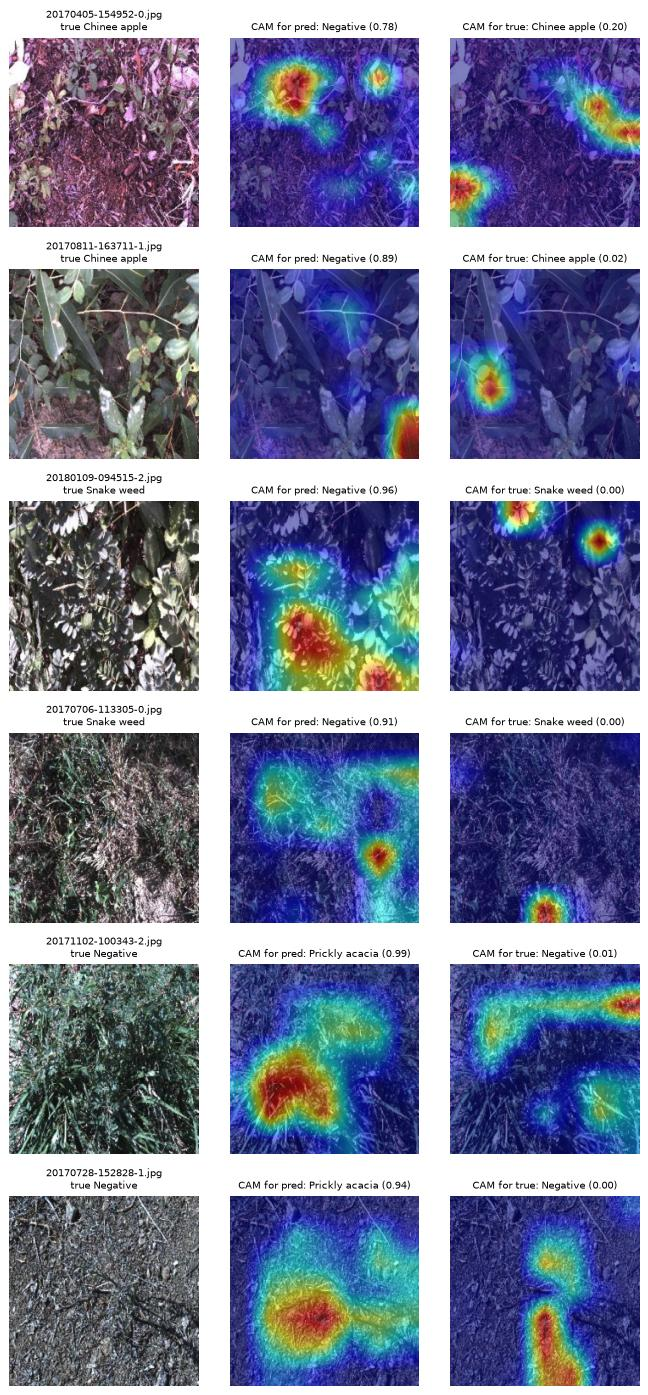

In [11]:
resnet, resnet_cfg = explain.load_cnn(CFG / f'{RESNET}.yaml', f'{RESNET}_s1')
top3 = top_pooled_confusions(metrics(f'{RESNET}_seeds'), k=3)

def stable_errors(true, pred, k=2):
    sub = stable[(stable.true == true) & (stable.pred_s1 == pred)]
    return sub.sort_values('mean_conf', ascending=False).head(k)

mistakes = pd.concat([stable_errors(t, p) for t, p, _ in top3])
fig = explain.gradcam_figure(resnet, resnet_cfg, list(mistakes.index), list(mistakes.true))
fig.savefig(FIG_DIR / 'gradcam_resnet_mistakes.png', bbox_inches='tight')

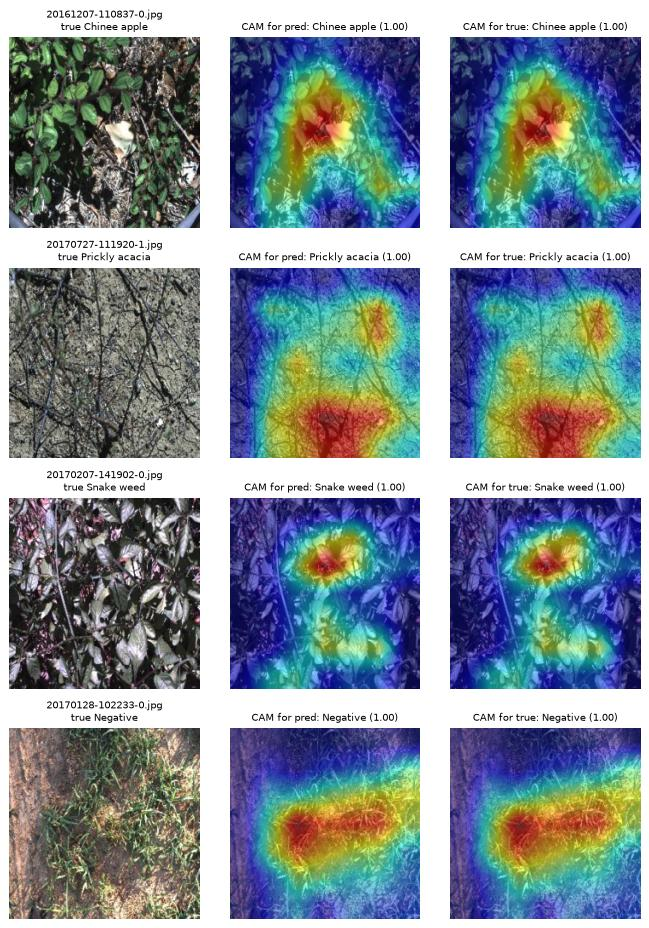

In [12]:
involved = sorted({c for t, p, _ in top3 for c in (t, p)}, key=CLASSES.index)
correct = pd.concat([test[(test.true == c) & (test.n_wrong == 0)].sort_values('mean_conf', ascending=False).head(1)
                     for c in involved])
fig = explain.gradcam_figure(resnet, resnet_cfg, list(correct.index), list(correct.true))
fig.savefig(FIG_DIR / 'gradcam_resnet_correct.png', bbox_inches='tight')

Same view for the simple CNN (seed 1), on its own most frequent confusions.

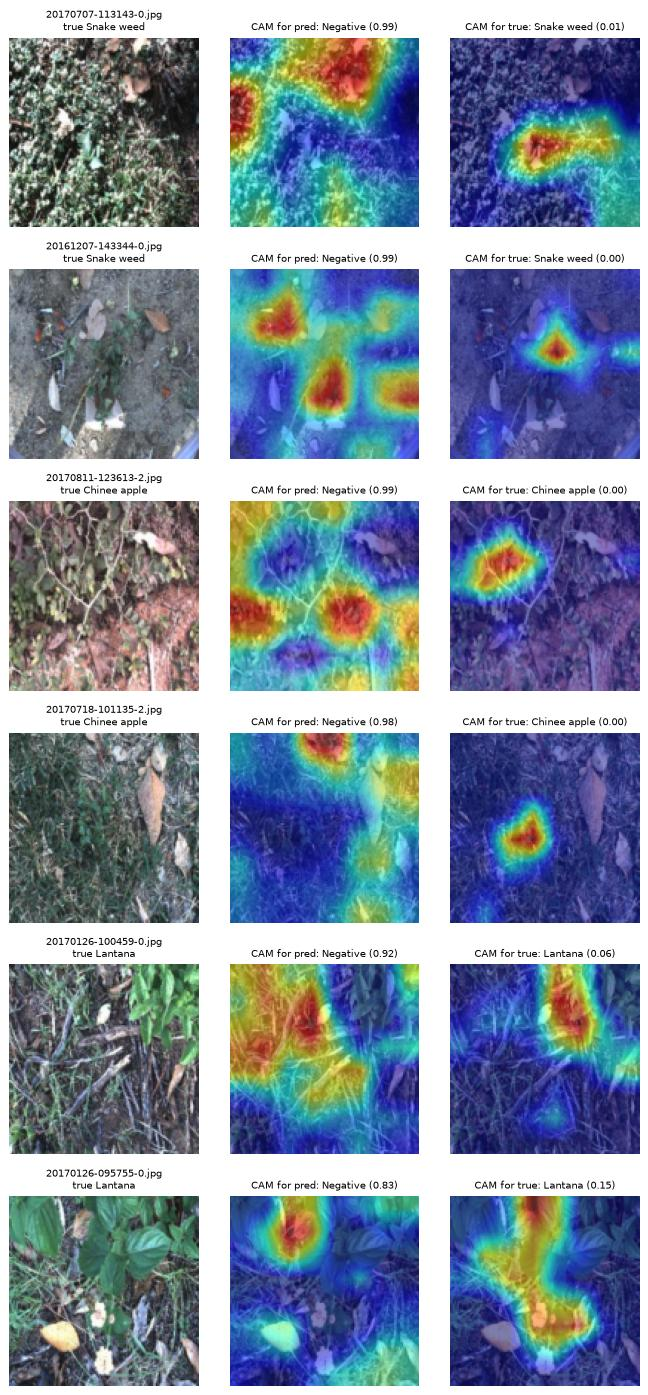

In [13]:
cnn, cnn_cfg = explain.load_cnn(CFG / f'{CNN}.yaml', f'{CNN}_s1')
cnn_csv = PREDS / f'{CNN}_s1_test.csv'
cnn_top = top_pooled_confusions(metrics(f'{CNN}_seeds'), k=3)
cnn_err = pd.concat([explain.confident_errors(cnn_csv, k=2, true=t, pred=p) for t, p, _ in cnn_top])
fig = explain.gradcam_figure(cnn, cnn_cfg, list(cnn_err.Filename), list(cnn_err.true))
fig.savefig(FIG_DIR / 'gradcam_simple_cnn_mistakes.png', bbox_inches='tight')

## 7. LIME: what the colour-histogram KNN responds to

The KNN has no spatial notion: it compares 96-bin HSV histograms of the whole image. LIME
switches superpixels off (black) at random, re-runs resize → histogram → KNN, and fits a
linear model: green superpixels push towards the predicted class, red ones away. Rows: the
KNN's two most frequent confusions (2 confident mistakes each), then 2 correct predictions.

Keep `02_baseline.ipynb` section 6 in mind: much of this KNN's accuracy comes from val/test images
whose nearest training histogram is a frame from the same capture session. A correct prediction
here may be that look-up, not recognition of the plant, even when LIME's green superpixels sit on
the leaves.

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

,Filename,true,pred,confidence
0,20170210-132736-0.jpg,Chinee apple,Negative,1.0
1,20170217-111024-0.jpg,Chinee apple,Negative,1.0
2,20170630-160252-0.jpg,Snake weed,Negative,1.0
3,20170630-155129-0.jpg,Snake weed,Negative,1.0
4,20180109-094515-2.jpg,Snake weed,Snake weed,1.0
5,20171122-104102-1.jpg,Rubber vine,Rubber vine,1.0


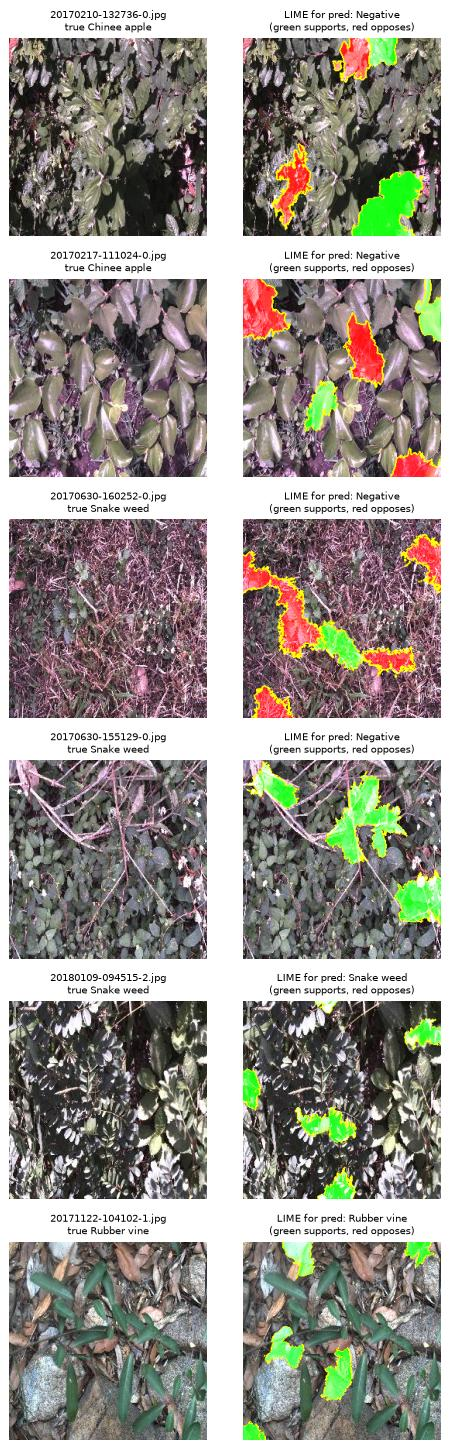

In [14]:
knn, knn_cfg, knn_feat = explain.fit_classical(CFG / f'knn_hist{SPLIT}.yaml')
knn_csv = PREDS / f'knn_hist{SPLIT}_test.csv'
knn_df = pd.read_csv(knn_csv)
knn_top = metrics('knn_hist' + SPLIT)['top_confusions_test'][:2]
picks = [explain.confident_errors(knn_csv, k=2, true=t, pred=p) for t, p, _ in knn_top]
ok = knn_df[(knn_df.true == knn_df.pred) & (knn_df.true != 'Negative')]
picks.append(ok.sort_values('confidence', ascending=False).drop_duplicates('true').head(2))
lime_rows = pd.concat(picks, ignore_index=True)
fig = explain.lime_knn_figure(knn, knn_cfg, knn_feat, list(lime_rows.Filename), list(lime_rows.true))
fig.savefig(FIG_DIR / 'lime_knn_hist.png', bbox_inches='tight')
lime_rows[['Filename', 'true', 'pred', 'confidence']]

## 8. Error-cause gallery

The 224 px ResNet's 24 most confident stable mistakes (or all of them, if fewer) (wrong in all 3 seeds), titled
`true -> predicted (mean confidence)`. The same images are written to
`results/error_analysis/resnet50_224_kaggle0_stable_errors_to_tag.csv` with an empty `cause` column:
the team tags each one as look-alike species / occlusion or blur / lighting or shadow /
possible label noise / other, and the counts go in the report.

cause options: ['look-alike species', 'occlusion / blur', 'lighting / shadow', 'possible label noise', 'other']
wrote results\error_analysis\resnet50_224_kaggle0_stable_errors_to_tag.csv


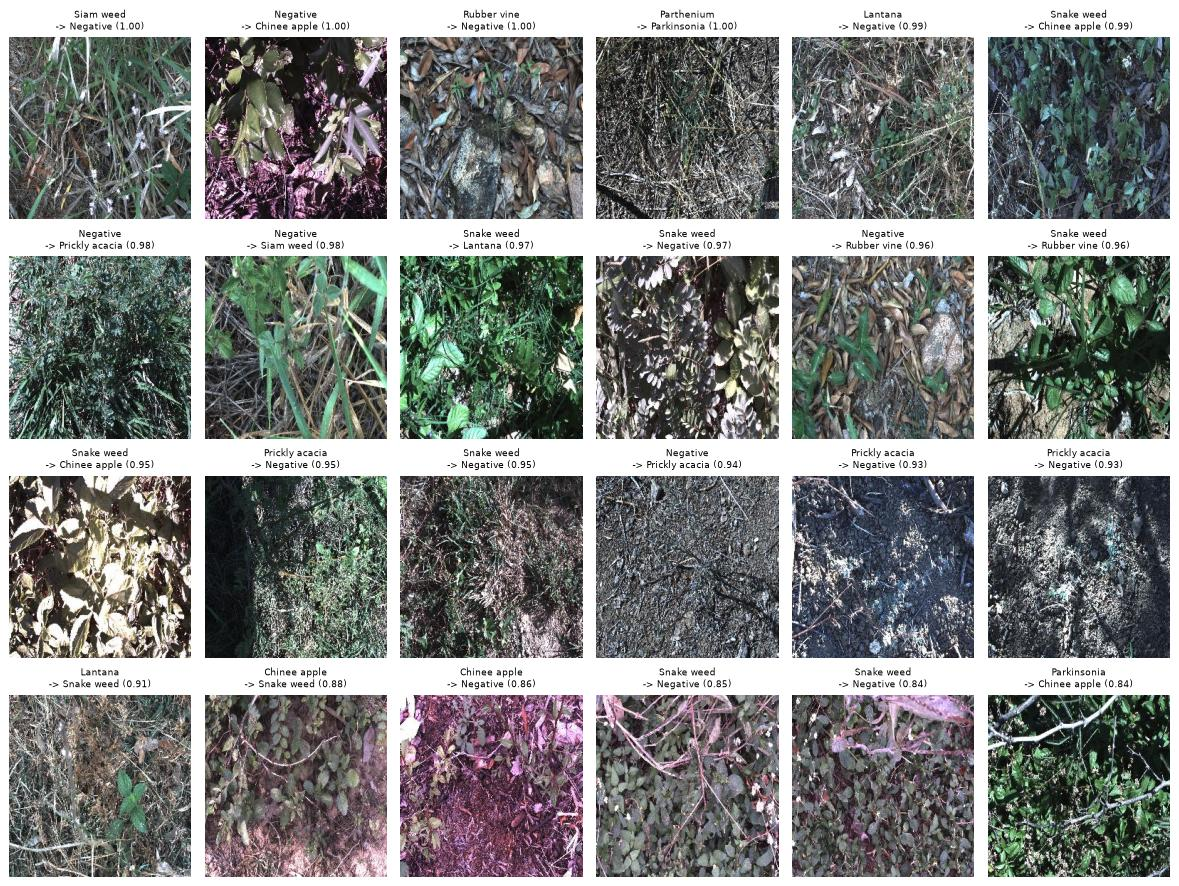

In [15]:
gallery = (stable.sort_values('mean_conf', ascending=False).head(24).round({'mean_conf': 4})
           .reset_index().rename(columns={'pred_s1': 'pred', 'mean_conf': 'confidence'}))
fig = explain.gallery_figure(gallery, IMG_DIR, ncols=6)
fig.savefig(FIG_DIR / 'gallery_resnet_stable_errors.png', bbox_inches='tight')
tag_csv = ROOT / 'results' / 'error_analysis' / 'resnet50_224_kaggle0_stable_errors_to_tag.csv'
explain.tagging_template(gallery, tag_csv)
print('cause options:', explain.CAUSES)
print('wrote', tag_csv.relative_to(ROOT))

## 9. Are mistakes darker, blurrier or less colourful?

If lighting or blur caused the errors, stable mistakes should differ from images every seed
got right. Because the class mix of the two groups differs (most mistakes involve Negative),
the comparison is also made **within** each class. Mann-Whitney U, two-sided; with several
tests, treat p-values above ~0.01 as no evidence.

In [16]:
stats = explain.image_stats(list(test.index), IMG_DIR).set_index('Filename').join(test)
stats['group'] = np.select([stats.n_wrong == 3, stats.n_wrong == 0], ['stable mistake', 'always right'], 'unstable')
STATS = ['brightness', 'saturation', 'contrast', 'sharpness']

def compare(df):
    a, b = df[df.group == 'stable mistake'], df[df.group == 'always right']
    out = {'n mistakes': len(a), 'n right': len(b)}
    for s in STATS:
        out[f'{s} median (mistake / right)'] = f'{a[s].median():.3f} / {b[s].median():.3f}'
        out[f'{s} p'] = mannwhitneyu(a[s], b[s]).pvalue if len(a) >= 5 else np.nan
    return out

rows = {'all classes': compare(stats)}
for c in CLASSES:
    sub = stats[stats.true == c]
    if (sub.group == 'stable mistake').sum() >= 10:
        rows[c] = compare(sub)
stat_table = pd.DataFrame(rows).T
stat_table

,n mistakes,n right,brightness median (mistake / right),brightness p,saturation median (mistake / right),saturation p,contrast median (mistake / right),contrast p,sharpness median (mistake / right),sharpness p
all classes,44,3349,0.388 / 0.419,0.0,0.187 / 0.178,0.407,0.251 / 0.220,0.0,0.382 / 0.283,0.011
Snake weed,11,176,0.387 / 0.358,0.105,0.195 / 0.180,0.75,0.256 / 0.245,0.363,0.266 / 0.212,0.212
Negative,11,1781,0.365 / 0.435,0.0,0.202 / 0.166,0.25,0.249 / 0.215,0.065,0.419 / 0.276,0.048


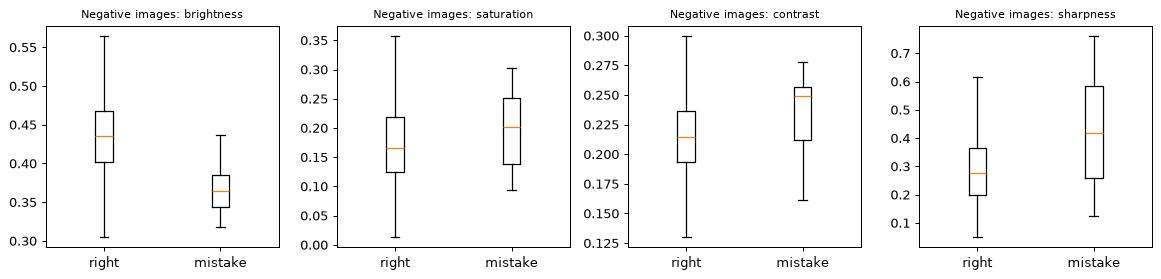

In [17]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
neg = stats[(stats.true == 'Negative') & (stats.group != 'unstable')]
for ax, s in zip(axes, STATS):
    data = [neg[neg.group == g][s] for g in ('always right', 'stable mistake')]
    ax.boxplot(data, showfliers=False)
    ax.set_xticks([1, 2], ['right', 'mistake'])
    ax.set_title(f'Negative images: {s}', fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / 'image_stats_negative.png', bbox_inches='tight')

## 10. Takeaways

Numbers are test macro F1 unless marked val. The augmented CNNs are mean ± std over 3 seeds;
the no-augmentation runs and the 256 px run have one seed each.

**Q1–Q2: classical baseline vs learned features.** The best classical model is KNN on HSV
colour histograms (0.613, vs 0.076 for always predicting Negative). Raw pixels and HOG stay below
0.24 with either learner, and logistic regression on the same histograms reaches only
0.375. KNN's lead over logistic regression comes from near-duplicate frames: when a val image's
nearest training histogram is from another day, KNN is no more accurate than logistic regression
(0.494 vs 0.490 accuracy; `02_baseline.ipynb` section 6). Learned features lift this to 0.905 ± 0.005 (simple CNN from scratch) and 0.923 ± 0.005
(ImageNet ResNet-50), both at 128 px. The seed spread is tiny next to these gaps.

**Q3: augmentation (128 px).** Augmentation helps both networks. ResNet-50: 0.870 → 0.923 on test
(+0.05) and 0.876 → 0.924 on val, about 10× the seed std. Without it the ResNet fits the
training set within a few epochs (train accuracy above 0.98 from epoch 7) and val F1 levels off
near 0.87; with flip/rotate/crop, train accuracy rises more slowly and val F1 keeps climbing to
0.92. Simple CNN: 0.870 → 0.905 (+0.035, about 7× the seed std). Without augmentation both
networks score the same (0.870), so the pretrained backbone pays off only once augmentation
stops it memorising the training set (+0.018 over the augmented simple CNN; the two use different
augmentations, random crop vs colour jitter, so this is not a pure pretraining effect). Details in
`03_cnn.ipynb` and `04_transfer.ipynb`.

**Q3: input size.** Training the same ResNet-50 at 224×224 px instead of 128×128 lifts it from
0.923 ± 0.005 to 0.965 ± 0.002 (val 0.924 → 0.966), about 10× the seed spread, and the val curve
climbs faster and more steadily from the first epochs. Going further to 256 px, the native size
of the images, scores *lower* on val (seed 1: 0.954 vs 0.966 at 224) with a noisier curve, so it
was rejected without a test score. One seed is not enough to explain the drop; a plausible cause
is that the ImageNet weights were trained at 224 px and objects appear 1.14× larger at 256.
Details in `04_transfer.ipynb` section 7.

**Test-time augmentation and the seed ensemble (no retraining).** Averaging each test image's
predictions over its 8 flip / 90° rotation views and the 3 seeds gives 0.948 at 128 px and
**0.973 at 224 px (accuracy 0.978), the best result here**. At 224 px most of the gain is
already in the single model: TTA adds +0.004 (0.969 ± 0.002) and the ensemble another +0.004.
On test the ensemble without TTA scores the same (0.973, accuracy 0.979), so at 224 px the 8 TTA
views add nothing once 3 seeds are averaged; val had picked ensemble + TTA by 0.001.
Both were chosen on val first (224 px: 0.966 → 0.968 → 0.970). A per-class offset against
Negative, tuned on val, did not generalise (+0.0003 cross-validated within val) and was not
used. The paper's 95.7% accuracy for ResNet-50 is a 5-fold average at 224×224 px, so it is not
a like-for-like comparison, and every test image has a training frame from the same capture session (point 7), which
flatters every number here.

**Q4: what stays confused, and why** (224 px single-model predictions without TTA).
1. **Weeds called Negative is still the main error, but it has halved.** Per run: Chinee apple →
   Negative 9.7, Snake weed → Negative 9.3, Prickly acacia → Negative 7.0, plus Negative →
   Prickly acacia 7.7 and Snake weed → Chinee apple 4.7 (at 128 px the top weed → Negative
   counts were 13.7–15.7 each). Snake weed (0.938) and Chinee apple (0.944) are still the two
   weakest classes, as for every model (128 px ResNet 0.88 / 0.87, simple CNN 0.83 / 0.86,
   KNN 0.48 / 0.43); Prickly acacia (0.948) is now third. Every other class is at 0.96 or above.
2. **About a quarter of the mistakes come from the images.** 158 test images are wrong in at
   least one seed (360 at 128 px); 44 (28%) are wrong in all three, and for 84% of those all three
   seeds pick the same wrong class. In seed 1's predictions, 19 of the 44 are weeds called
   Negative, 11 are Negative photos called a weed (5 of them Prickly acacia), and 8 are swaps between
   Snake weed, Chinee apple and Lantana. The rest change from seed to seed, i.e. training noise.
3. **Grad-CAM: when the ResNet misses a weed, it is looking at the ground.** On its confident
   Chinee apple / Snake weed → Negative mistakes, the Negative map sits on dark leaf litter,
   grass or soil, while the map for the true class (probability ≤ 0.20) is a small spot on one
   leaf or at the edge of the frame. Negative frames called Prickly acacia are
   bare soil or grass with thin twigs, which look like Prickly acacia's own photos (thin dark
   branches over bare ground, as in the correct example). On correct predictions the map covers
   the plant itself. The simple CNN (128 px, unchanged) shows the same pattern with patchier maps.
4. **LIME: the colour-histogram KNN reacts to overall colour, not to a plant.** In its two
   correct examples the supporting superpixels sit on the plant's leaves (Snake weed, Rubber
   vine). In its mistakes, support and opposition are scattered over leaves and litter with no
   consistent pattern, and several of the mistaken photos have a pink/purple colour cast, which
   a whole-image histogram cannot tell apart from plant colour. (LIME blacks out superpixels,
   which itself shifts the histogram, so read these maps qualitatively.)
5. **Gallery: four patterns.** (a) The weed is sparse or small in a frame of leaf litter, grass
   or bare soil (Siam weed, Rubber vine, Lantana, Prickly acacia → Negative); (b) Negative frames
   full of other broad-leaved plants or twigs, called a weed (→ Chinee apple, Siam weed, Rubber
   vine, Prickly acacia); (c) look-alike foliage between weeds (Snake weed ↔ Chinee apple,
   Snake weed → Lantana / Rubber vine); (d) photos with a pink/purple colour cast. The model gives
   these 0.84–1.00 confidence, so its confidence is no warning sign. The team's tags in
   `results/error_analysis/resnet50_224_kaggle0_stable_errors_to_tag.csv` turn this into counts.
6. **Not blur; Negative mistakes are darker.** Negative photos called a weed are darker than
   Negative photos every seed gets right (brightness 0.365 vs 0.435, p < 0.001, 11 vs 1,781 images).
   Across weed photos, stable mistakes are no darker (0.39 vs 0.39, p = 0.77) or blurrier: if
   anything they are slightly sharper (sharpness p = 0.16) and higher-contrast (p = 0.015), which
   fits cluttered frames more than poor photos. The all-classes brightness gap (0.39 vs 0.42)
   mostly reflects class mix: 75% of the stable mistakes are weed photos, which are darker than
   Negative ones. With only 44 stable mistakes, treat the per-class tests as weak evidence.
7. **Every test image comes from a session the model trained on.** All but 3 test images have
   a training image taken within 10 minutes (96% within a minute), usually of the same species
   (96%), because the authors' folds split by image, not by session. Mistakes are more common
   where that help is weaker: images whose nearest training frame is 1–10 minutes away are
   wrong in at least one seed about 3× as often (12% vs 4%). For stable mistakes the
   nearest-in-time training frame is a different species 25% of the time, against 3% for
   images always classified right. The test scores therefore measure new frames from known
   sessions and probably overstate accuracy on a new field.

**What this suggests (not run).** The remaining error is mostly a weed that is sparse or small in
a cluttered frame being called Negative, bare-ground Negative frames called Prickly acacia, and
Snake weed ↔ Chinee apple. Class weighting or class-balanced sampling (rather than a fixed
offset, which did not generalise), longer training at 224 px (val F1 was still rising slowly at
epoch 30 for seed 1), and white-balance correction for the colour-cast photos are the natural next
experiments. To measure accuracy on unseen fields, a split grouped by capture session (or by site) would be
the honest test; expect lower scores than the 0.973 here, especially for KNN.